In [1]:
%pip install umap-learn

   ---------------------------------------- 0.0/2.8 MB ? eta -:--:--
   -------------- ------------------------- 1.0/2.8 MB 5.4 MB/s eta 0:00:01
   --------------------------------- ------ 2.4/2.8 MB 5.6 MB/s eta 0:00:01
   ---------------------------------------- 2.8/2.8 MB 5.6 MB/s  0:00:00
   ---------------------------------------- 0.0/43.0 MB ? eta -:--:--
    --------------------------------------- 1.0/43.0 MB 6.6 MB/s eta 0:00:07
   - -------------------------------------- 2.1/43.0 MB 5.3 MB/s eta 0:00:08
   -- ------------------------------------- 3.1/43.0 MB 5.4 MB/s eta 0:00:08
   --- ------------------------------------ 4.2/43.0 MB 5.5 MB/s eta 0:00:08
   ---- ----------------------------------- 5.2/43.0 MB 5.2 MB/s eta 0:00:08
   ----- ---------------------------------- 6.3/43.0 MB 5.1 MB/s eta 0:00:08
   ------- -------------------------------- 7.6/43.0 MB 5.4 MB/s eta 0:00:07
   -------- ------------------------------- 8.9/43.0 MB 5.5 MB/s eta 0:00:07
   --------- -------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [1]:
# ============================================================
# STEP 01.6 — UMAP VISUALIZATION
# Knowledge-Level Cross-Modal Representation Analysis
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import sys

import umap.umap_ as umap

print("=" * 100)
print("STEP 01.6 — UMAP VISUALIZATION")
print("Knowledge-Level Cross-Modal Representation Analysis")
print("=" * 100)

# ------------------------------------------------------------
# Resolve Project Root
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

while PROJECT_ROOT.name != "GAN-Enhanced-Multimodal-ASD-Screening":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise RuntimeError("Project root could not be found.")
    PROJECT_ROOT = PROJECT_ROOT.parent

print("\nProject Root:")
print(PROJECT_ROOT)

# ------------------------------------------------------------
# Define Directories
# ------------------------------------------------------------

FUSION_DIR = PROJECT_ROOT / "05_multimodal_fusion"

FIGURE_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "figures"
)

REPORT_DIR = (
    PROJECT_ROOT
    / "06_cross_modal_learning"
    / "01_embedding_analysis"
    / "reports"
)

FIGURE_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

print("\nFigure Directory:")
print(FIGURE_DIR)

print("\nReport Directory:")
print(REPORT_DIR)

C:\Users\shasw\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


STEP 01.6 — UMAP VISUALIZATION
Knowledge-Level Cross-Modal Representation Analysis

Project Root:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening

Figure Directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures

Report Directory:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports


In [2]:
# ============================================================
# LOAD FROZEN BASELINE EMBEDDINGS
# ============================================================

genetic_embeddings = np.load(
    FUSION_DIR / "genetic_32d_normalized.npy"
)

genetic_labels = np.load(
    FUSION_DIR / "genetic_targets.npy"
)

behavioral_embeddings = np.load(
    FUSION_DIR / "behavioral_32d_normalized.npy"
)

behavioral_labels = np.load(
    FUSION_DIR / "behavioral_targets.npy"
)

environmental_embeddings = np.load(
    FUSION_DIR / "environmental_32d_normalized.npy"
)

environmental_labels = np.load(
    FUSION_DIR / "environmental_targets.npy"
)

print("=" * 100)
print("FROZEN 32D EMBEDDINGS LOADED")
print("=" * 100)

print("\nGenetic:")
print("Embeddings:", genetic_embeddings.shape)
print("Labels:", genetic_labels.shape)

print("\nBehavioral:")
print("Embeddings:", behavioral_embeddings.shape)
print("Labels:", behavioral_labels.shape)

print("\nEnvironmental:")
print("Embeddings:", environmental_embeddings.shape)
print("Labels:", environmental_labels.shape)

FROZEN 32D EMBEDDINGS LOADED

Genetic:
Embeddings: (116, 32)
Labels: (116,)

Behavioral:
Embeddings: (880, 32)
Labels: (880,)

Environmental:
Embeddings: (47768, 32)
Labels: (47768,)


In [3]:
# ============================================================
# BALANCED CLASS-AWARE SAMPLING
# ============================================================

RANDOM_STATE = 42

rng = np.random.RandomState(RANDOM_STATE)

# Reference class counts from Genetic modality
reference_class_0 = np.sum(genetic_labels == 0)
reference_class_1 = np.sum(genetic_labels == 1)

print("=" * 100)
print("BALANCED CLASS-AWARE SAMPLING")
print("=" * 100)

print(f"\nReference counts:")
print(f"Class 0: {reference_class_0}")
print(f"Class 1: {reference_class_1}")


def balanced_sample(embeddings, labels, n_class_0, n_class_1, rng):
    """
    Create class-aware balanced sample.

    This does NOT create patient-level matching.
    It only ensures fair class-distribution comparison
    across representation spaces.
    """

    class_0_indices = np.where(labels == 0)[0]
    class_1_indices = np.where(labels == 1)[0]

    selected_0 = rng.choice(
        class_0_indices,
        size=n_class_0,
        replace=False
    )

    selected_1 = rng.choice(
        class_1_indices,
        size=n_class_1,
        replace=False
    )

    selected_indices = np.concatenate(
        [selected_0, selected_1]
    )

    rng.shuffle(selected_indices)

    return (
        embeddings[selected_indices],
        labels[selected_indices]
    )


# Genetic remains complete reference dataset
genetic_balanced = genetic_embeddings.copy()
genetic_labels_balanced = genetic_labels.copy()


# Behavioral sampling
behavioral_balanced, behavioral_labels_balanced = balanced_sample(
    behavioral_embeddings,
    behavioral_labels,
    reference_class_0,
    reference_class_1,
    rng
)


# Environmental sampling
environmental_balanced, environmental_labels_balanced = balanced_sample(
    environmental_embeddings,
    environmental_labels,
    reference_class_0,
    reference_class_1,
    rng
)


# Summary
sampling_summary = pd.DataFrame({
    "Modality": [
        "Genetic",
        "Behavioral",
        "Environmental"
    ],
    "Class_0_Count": [
        np.sum(genetic_labels_balanced == 0),
        np.sum(behavioral_labels_balanced == 0),
        np.sum(environmental_labels_balanced == 0)
    ],
    "Class_1_Count": [
        np.sum(genetic_labels_balanced == 1),
        np.sum(behavioral_labels_balanced == 1),
        np.sum(environmental_labels_balanced == 1)
    ]
})

sampling_summary["Total_Samples"] = (
    sampling_summary["Class_0_Count"]
    + sampling_summary["Class_1_Count"]
)

print("\nBalanced Sampling Summary:\n")
display(sampling_summary)

BALANCED CLASS-AWARE SAMPLING

Reference counts:
Class 0: 29
Class 1: 87

Balanced Sampling Summary:



,Modality,Class_0_Count,Class_1_Count,Total_Samples
0,Genetic,29,87,116
1,Behavioral,29,87,116
2,Environmental,29,87,116


In [4]:
# ============================================================
# COMBINE REPRESENTATIONS
# ============================================================

combined_embeddings = np.vstack([
    genetic_balanced,
    behavioral_balanced,
    environmental_balanced
])

combined_labels = np.concatenate([
    genetic_labels_balanced,
    behavioral_labels_balanced,
    environmental_labels_balanced
])

combined_modalities = np.array(
    ["Genetic"] * len(genetic_balanced)
    + ["Behavioral"] * len(behavioral_balanced)
    + ["Environmental"] * len(environmental_balanced)
)

print("=" * 100)
print("COMBINED KNOWLEDGE-LEVEL REPRESENTATION SPACE")
print("=" * 100)

print("\nCombined embedding shape:")
print(combined_embeddings.shape)

print("\nTotal samples by modality:")
print(pd.Series(combined_modalities).value_counts())

print("\nTotal samples by class:")
print(pd.Series(combined_labels).value_counts().sort_index())

print("""
IMPORTANT:
These samples are NOT patient-matched.

UMAP is being used to examine the global geometric
relationship between learned modality representations.

This is KNOWLEDGE-LEVEL cross-modal analysis.
""")

COMBINED KNOWLEDGE-LEVEL REPRESENTATION SPACE

Combined embedding shape:
(348, 32)

Total samples by modality:
Genetic          116
Behavioral       116
Environmental    116
Name: count, dtype: int64

Total samples by class:
0     87
1    261
Name: count, dtype: int64

IMPORTANT:
These samples are NOT patient-matched.

UMAP is being used to examine the global geometric
relationship between learned modality representations.

This is KNOWLEDGE-LEVEL cross-modal analysis.



In [5]:
# ============================================================
# RUN UMAP
# ============================================================

print("=" * 100)
print("RUNNING UMAP")
print("=" * 100)

UMAP_N_NEIGHBORS = 15
UMAP_MIN_DIST = 0.1
UMAP_METRIC = "euclidean"
RANDOM_STATE = 42

reducer = umap.UMAP(
    n_components=2,
    n_neighbors=UMAP_N_NEIGHBORS,
    min_dist=UMAP_MIN_DIST,
    metric=UMAP_METRIC,
    random_state=RANDOM_STATE
)

umap_coordinates = reducer.fit_transform(
    combined_embeddings
)

print("\nUMAP completed successfully.")

print("\nOutput shape:")
print(umap_coordinates.shape)

print("\nUMAP Parameters:")
print(f"n_neighbors : {UMAP_N_NEIGHBORS}")
print(f"min_dist    : {UMAP_MIN_DIST}")
print(f"metric      : {UMAP_METRIC}")
print(f"random_state: {RANDOM_STATE}")

RUNNING UMAP


C:\Users\shasw\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(



UMAP completed successfully.

Output shape:
(348, 2)

UMAP Parameters:
n_neighbors : 15
min_dist    : 0.1
metric      : euclidean
random_state: 42


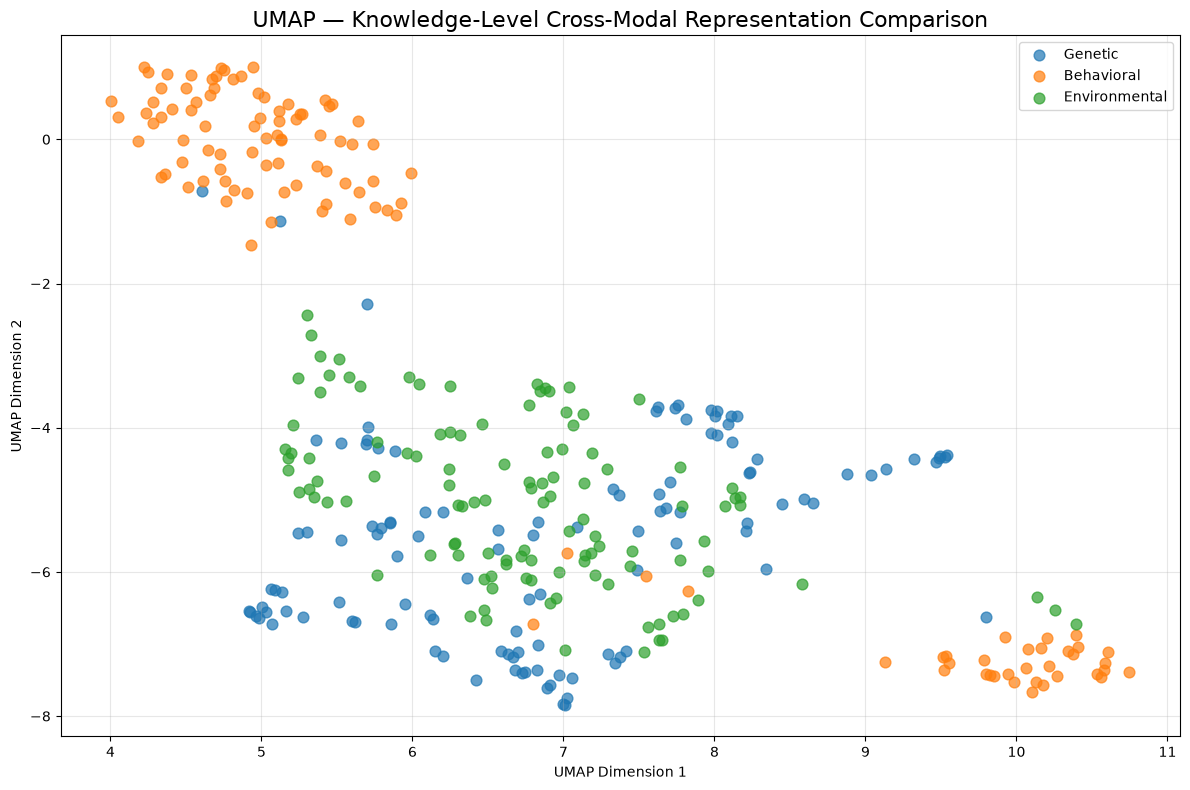

Figure saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_06_umap_by_modality.png


In [6]:
# ============================================================
# UMAP — MODALITY COMPARISON
# ============================================================

plt.figure(figsize=(12, 8))

modalities = [
    "Genetic",
    "Behavioral",
    "Environmental"
]

for modality in modalities:

    mask = combined_modalities == modality

    plt.scatter(
        umap_coordinates[mask, 0],
        umap_coordinates[mask, 1],
        label=modality,
        alpha=0.7,
        s=60
    )

plt.title(
    "UMAP — Knowledge-Level Cross-Modal Representation Comparison",
    fontsize=16
)

plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()

output_path = (
    FIGURE_DIR
    / "01_06_umap_by_modality.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:")
print(output_path)

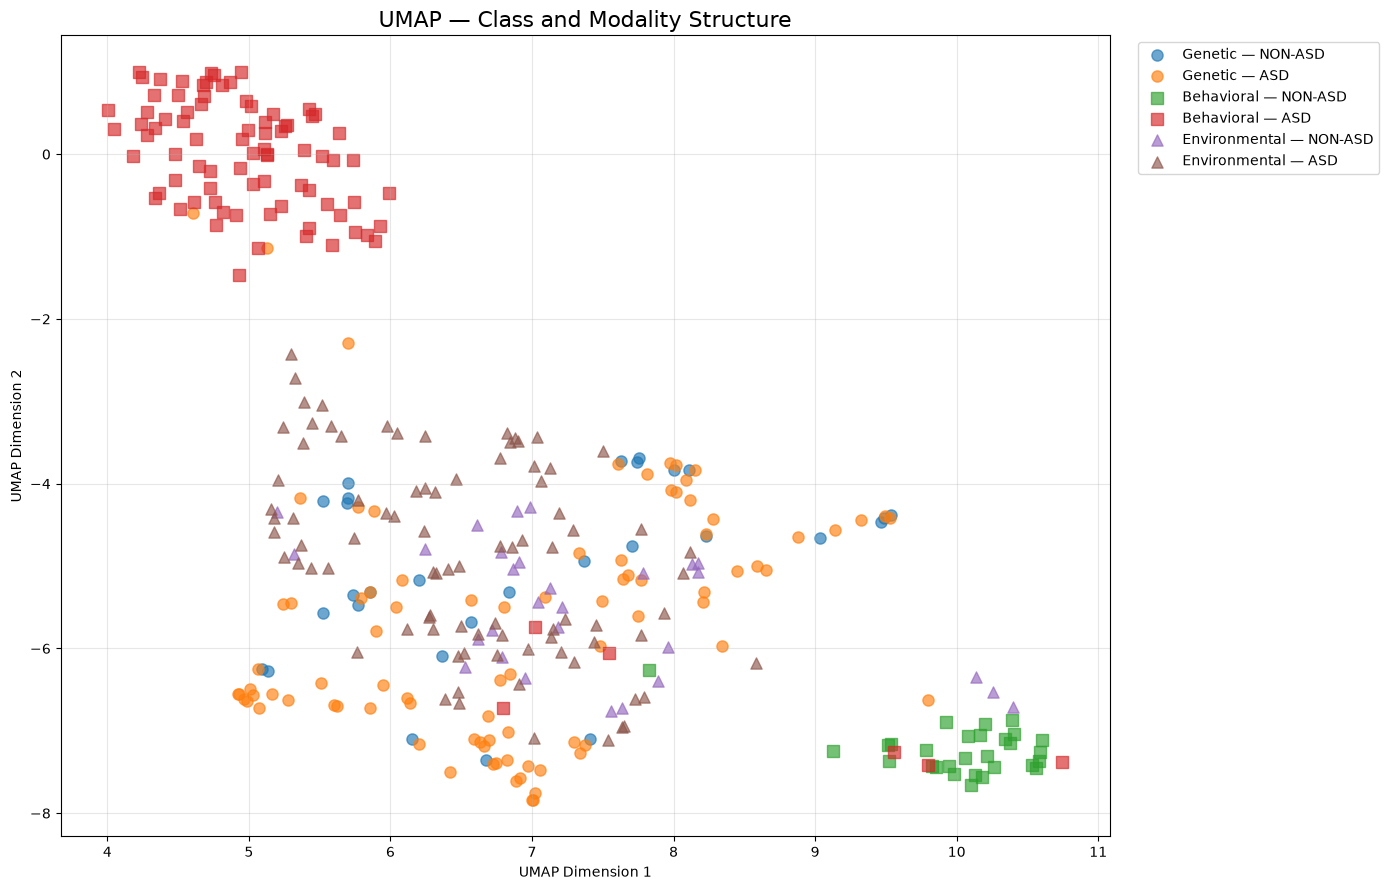

Figure saved:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\figures\01_06_umap_class_and_modality.png


In [7]:
# ============================================================
# UMAP — CLASS AND MODALITY STRUCTURE
# ============================================================

plt.figure(figsize=(14, 9))

modality_markers = {
    "Genetic": "o",
    "Behavioral": "s",
    "Environmental": "^"
}

class_labels = {
    0: "NON-ASD",
    1: "ASD"
}

for modality in modalities:

    for class_value in [0, 1]:

        mask = (
            (combined_modalities == modality)
            & (combined_labels == class_value)
        )

        plt.scatter(
            umap_coordinates[mask, 0],
            umap_coordinates[mask, 1],
            marker=modality_markers[modality],
            alpha=0.65,
            s=65,
            label=f"{modality} — {class_labels[class_value]}"
        )

plt.title(
    "UMAP — Class and Modality Structure",
    fontsize=16
)

plt.xlabel("UMAP Dimension 1")
plt.ylabel("UMAP Dimension 2")

plt.legend(
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.grid(alpha=0.3)

plt.tight_layout()

output_path = (
    FIGURE_DIR
    / "01_06_umap_class_and_modality.png"
)

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Figure saved:")
print(output_path)

In [8]:
# ============================================================
# SAVE UMAP COORDINATES
# ============================================================

coordinates_df = pd.DataFrame({
    "UMAP_1": umap_coordinates[:, 0],
    "UMAP_2": umap_coordinates[:, 1],
    "Modality": combined_modalities,
    "Class": combined_labels
})

coordinates_path = (
    REPORT_DIR
    / "01_06_umap_coordinates.csv"
)

coordinates_df.to_csv(
    coordinates_path,
    index=False
)


# ============================================================
# SAVE CONFIGURATION
# ============================================================

configuration_df = pd.DataFrame({
    "Parameter": [
        "Analysis Type",
        "Patient-Level Matching",
        "Genetic Samples",
        "Behavioral Samples",
        "Environmental Samples",
        "Total Samples",
        "Embedding Dimension",
        "UMAP Components",
        "n_neighbors",
        "min_dist",
        "Metric",
        "Random State"
    ],
    "Value": [
        "Knowledge-Level Cross-Modal Representation Analysis",
        "NOT USED",
        len(genetic_balanced),
        len(behavioral_balanced),
        len(environmental_balanced),
        len(combined_embeddings),
        combined_embeddings.shape[1],
        2,
        UMAP_N_NEIGHBORS,
        UMAP_MIN_DIST,
        UMAP_METRIC,
        RANDOM_STATE
    ]
})

configuration_path = (
    REPORT_DIR
    / "01_06_umap_configuration_summary.csv"
)

configuration_df.to_csv(
    configuration_path,
    index=False
)


print("=" * 100)
print("UMAP REPORTS SAVED")
print("=" * 100)

print("\nCoordinates:")
print(coordinates_path)

print("\nConfiguration:")
print(configuration_path)

UMAP REPORTS SAVED

Coordinates:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_06_umap_coordinates.csv

Configuration:
C:\Users\shasw\Documents\GitHub\GAN-Enhanced-Multimodal-ASD-Screening\06_cross_modal_learning\01_embedding_analysis\reports\01_06_umap_configuration_summary.csv


In [9]:
# ============================================================
# STEP 01.6 — FINAL SUMMARY
# ============================================================

print("=" * 100)
print("STEP 01.6 — UMAP VISUALIZATION COMPLETED")
print("=" * 100)

print("""
Analysis Type:
Knowledge-Level Cross-Modal Representation Analysis

Patient-level matching:
NOT USED

Balanced Sampling:
""")

print(f"Genetic       : {len(genetic_balanced)}")
print(f"Behavioral    : {len(behavioral_balanced)}")
print(f"Environmental : {len(environmental_balanced)}")

print(f"\nTotal combined samples: {len(combined_embeddings)}")

print("""
Generated Figures:
1. 01_06_umap_by_modality.png
2. 01_06_umap_class_and_modality.png

Generated Reports:
1. 01_06_umap_coordinates.csv
2. 01_06_umap_configuration_summary.csv

UMAP Configuration:
""")

print(f"n_neighbors : {UMAP_N_NEIGHBORS}")
print(f"min_dist    : {UMAP_MIN_DIST}")
print(f"metric      : {UMAP_METRIC}")
print(f"random_state: {RANDOM_STATE}")

print("=" * 100)
print("✓ STEP 01.6 COMPLETED")
print("✓ KNOWLEDGE-LEVEL ANALYSIS PRESERVED")
print("✓ NO PATIENT-LEVEL ASSUMPTIONS MADE")
print("✓ READY FOR CROSS-MODAL SIMILARITY ANALYSIS")
print("=" * 100)

STEP 01.6 — UMAP VISUALIZATION COMPLETED

Analysis Type:
Knowledge-Level Cross-Modal Representation Analysis

Patient-level matching:
NOT USED

Balanced Sampling:

Genetic       : 116
Behavioral    : 116
Environmental : 116

Total combined samples: 348

Generated Figures:
1. 01_06_umap_by_modality.png
2. 01_06_umap_class_and_modality.png

Generated Reports:
1. 01_06_umap_coordinates.csv
2. 01_06_umap_configuration_summary.csv

UMAP Configuration:

n_neighbors : 15
min_dist    : 0.1
metric      : euclidean
random_state: 42
✓ STEP 01.6 COMPLETED
✓ KNOWLEDGE-LEVEL ANALYSIS PRESERVED
✓ NO PATIENT-LEVEL ASSUMPTIONS MADE
✓ READY FOR CROSS-MODAL SIMILARITY ANALYSIS
